In [3]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
device = "cuda" if torch.cuda.is_available() else "cpu"
train_all = datasets.MNIST(root="data", train=True, download=True,
                           transform=transforms.ToTensor())
g = torch.Generator().manual_seed(0) # 2주차와 같은 분리
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
print(len(train_loader), len(val_loader)) # → 782 40

782 40


In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flat = nn.Flatten() # 바뀐 곳 1 (N, 1, 28, 28) → (N, 784)
        self.fc1 = nn.Linear(784, 100)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(100, 10)
    def forward(self, x):
        x = self.flat(x) # 바뀐 곳 2, 먼저 편다
        return self.fc2(self.act(self.fc1(x)))
    
loss_fn = nn.CrossEntropyLoss()
print(MLP()(torch.zeros(2, 1, 28, 28)).shape) # → torch.Size([2, 10])

torch.Size([2, 10])


In [5]:
import torch
import torch.nn as nn
logits = torch.tensor([[2.0, 1.0, 0.1]]) # 샘플 1개, 클래스 3개의 점수
target = torch.tensor([0]) # 정답은 0번 클래스
p = torch.softmax(logits, dim=1) # 점수 → 확률
print(p) # → tensor([[0.6590, 0.2424, 0.0986]])
print(-torch.log(p[0, 0])) # → tensor(0.4170) 정답 확률의 -log
loss_fn = nn.CrossEntropyLoss()
print(loss_fn(logits, target)) # → tensor(0.4170) 같은 값, softmax와 -log를 한 번에

tensor([[0.6590, 0.2424, 0.0986]])
tensor(0.4170)
tensor(0.4170)


In [6]:
torch.manual_seed(0)
model = MLP().to(device) # 학습 전 모델
x, y = next(iter(train_loader)) # 배치 하나 꺼내기
x, y = x.to(device), y.to(device) # 펴기는 이제 모델이 한다
p = torch.softmax(model(x), dim=1) # 64개 샘플 × 10개 확률
print(round(p.min().item(), 2), round(p.max().item(), 2))
# → (예) 0.08 0.12
print(round(loss_fn(model(x), y).item(), 4)) # → (예) 2.2942 첫 loss
print(round(-torch.log(torch.tensor(0.1)).item(), 4)) # → 2.3026 (-log(1/10))

0.08 0.12
2.2942
2.3026


In [7]:
import torch
import torch.nn as nn
loss_fn = nn.CrossEntropyLoss()
labels = torch.tensor([0, 1, 2, 0]) # 샘플 4개의 정답
out_a = torch.tensor([[4.0, 0.0, 0.0], [0.0, 4.0, 0.0], # 모델 A, 확신하며 맞힌다
 [0.0, 0.0, 4.0], [0.0, 2.0, 0.0]])
out_b = torch.tensor([[1.0, 0.8, 0.0], [0.8, 1.0, 0.0], # 모델 B, 겨우 맞힌다
 [0.0, 0.8, 1.0], [0.0, 2.0, 0.0]])
print((out_a.argmax(dim=1) == labels).sum().item(), (out_b.argmax(dim=1) == labels).sum().item())
# → 3 3 맞힌 개수는 같다
print(round(loss_fn(out_a, labels).item(), 4), round(loss_fn(out_b, labels).item(), 4))
# → 0.5869 1.1467 (loss는 B가 약 2배)

3 3
0.5869 1.1467


In [8]:
import torch
import torch.nn as nn
print(-torch.log(torch.tensor([0.9, 0.5, 0.1]))) # 1 정답 확률별 loss
# → tensor([0.1054, 0.6931, 2.3026])
loss_fn = nn.CrossEntropyLoss()
logits = torch.tensor([[4.0, 1.0, 0.1]]) # 2 정답 점수를 4.0으로
print(loss_fn(logits, torch.tensor([0])))
# → tensor(0.0677) (0.4170보다 작아졌다)
logits = torch.tensor([[2.0, 1.0, 0.1]]) # 3 원래 점수에서
print(loss_fn(logits, torch.tensor([2]))) # 정답만 2번으로
# → tensor(2.3170)

tensor([0.1054, 0.6931, 2.3026])
tensor(0.0677)
tensor(2.3170)


In [9]:
import torch
x, t = torch.tensor(2.0), torch.tensor(5.0) # 입력 x와 정답 t
w = torch.tensor(3.0, requires_grad=True) # 파라미터 두 개
b = torch.tensor(1.0, requires_grad=True)
pred = w * x + b # forward, 예측
loss = (pred - t) ** 2 # forward, loss
loss.backward() # backward
print(pred.item(), loss.item()) # → 7.0 4.0
print(w.grad, b.grad) # → tensor(8.) tensor(4.) 손으로 구한 8과 4
with torch.no_grad(): # 기울기 반대 방향으로 한 걸음
 w -= 0.05 * w.grad
 b -= 0.05 * b.grad
print(round(((w * x + b - t) ** 2).item(), 4)) # → 1.0 (loss가 4에서 1로)

7.0 4.0
tensor(8.) tensor(4.)
1.0


In [10]:
import torch
import torch.nn as nn
loss_fn = nn.CrossEntropyLoss()
logits = torch.tensor([[2.0, 1.0, 0.1]], requires_grad=True) # 예제 4-1의 점수
loss = loss_fn(logits, torch.tensor([0])) # 정답은 0번
loss.backward()
print(torch.softmax(logits.detach(), dim=1)) # → tensor([[0.6590, 0.2424, 0.0986]])
print(logits.grad)

tensor([[0.6590, 0.2424, 0.0986]])
tensor([[-0.3410,  0.2424,  0.0986]])


In [11]:
torch.manual_seed(0) # 예제 4-2와 같은 모델, 같은 배치
model = MLP().to(device)
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
loss = loss_fn(model(x), y)
print(model.fc1.weight.grad) # → None (아직 없음)
loss.backward() # 역전파 한 줄
print(model.fc1.weight.grad.shape) # → torch.Size([100, 784])
print(model.fc2.bias.grad.shape) # → torch.Size([10])
print(sum(p.grad.numel() for p in model.parameters())) # → 79510

None
torch.Size([100, 784])
torch.Size([10])
79510


In [12]:
opt = torch.optim.SGD(model.parameters(), lr=0.1) # 갱신 규칙 SGD
b0 = model.fc2.bias[0].item() # 파라미터 하나의 갱신 전 값
g0 = model.fc2.bias.grad[0].item() # 그 파라미터의 기울기
opt.step() # 79,510개를 한 번에 갱신
print(round(b0 - 0.1 * g0, 4)) # → (예) 0.0894 손으로 계산한 값
print(round(model.fc2.bias[0].item(), 4)) # → (예) 0.0894 (step 후 실제 값)
print(round(loss.item(), 4), round(loss_fn(model(x), y).item(), 4))
# → (예) 2.2942 2.2643 같은 배치의 loss가 줄었다

0.0894
0.0894
2.2942 2.2643


In [13]:
opt.zero_grad() # 기울기 지우기
loss_fn(model(x), y).backward() # 기울기 계산
g1 = model.fc2.bias.grad[0].item()
loss_fn(model(x), y).backward() # zero_grad 없이 같은 계산을 한 번 더
g2 = model.fc2.bias.grad[0].item()
print(round(g2 / g1, 4)) # → 2.0 덮어쓰지 않고 더해졌다 (누적

2.0


In [14]:
logits = torch.tensor([[2.0, 1.0, 0.1]], requires_grad=True) # logits 3개
target = torch.tensor([2]) # 1 정답을 2번으로
opt = torch.optim.SGD([logits], lr=1.0) # 파라미터 목록 자리에 [logits]
loss = loss_fn(logits, target)
opt.zero_grad(); loss.backward()
print(logits.grad) # → tensor([[ 0.6590, 0.2424, -0.9014]]) (정답 칸만 음수)
opt.step() # 2 한 걸음
print(round(loss.item(), 4), round(loss_fn(logits, target).item(), 4))
# → 2.317 1.1594 (loss가 줄었다)
for step in range(10): # 3 네 줄을 10번
 loss = loss_fn(logits, target)
 opt.zero_grad(); loss.backward(); opt.step()
print(torch.softmax(logits.detach(), dim=1))
# → tensor([[0.0361, 0.0305, 0.9334]]) (정답 확률이 0.93으로)

tensor([[ 0.6590,  0.2424, -0.9014]])
2.317 1.1594
tensor([[0.0361, 0.0305, 0.9334]])


In [15]:
torch.manual_seed(0)
model = MLP().to(device) # 새 모델과 opt로 시작
opt = torch.optim.SGD(model.parameters(), lr=0.1)
x, y = next(iter(train_loader)) # 학습할 배치 하나 고정
x, y = x.to(device), y.to(device)
for step in range(100): # ① 같은 배치로 100 step
 loss = loss_fn(model(x), y)
 opt.zero_grad(); loss.backward(); opt.step()
 if step % 20 == 0:
  print(step, round(loss.item(), 4)) # (예) 0 2.2942 ... 80 0.209 (5줄)
print((model(x).argmax(dim=1) == y).sum().item()) # → (예) 64 (②)
x, y = next(iter(val_loader)) # ③ 검증 데이터의 배치 (처음 보는 256개)
x, y = x.to(device), y.to(device)
print((model(x).argmax(dim=1) == y).sum().item(), len(y)) # → (예) 165 256

0 2.2942


20 1.5677
40 0.7659
60 0.373
80 0.209
64
165 256


In [16]:
import torch
w = torch.tensor(1.0, requires_grad=True)
with torch.no_grad(): # 평가용 블록 안에서 loss를 만들면
 loss = (w * 3 - 1) ** 2
try:
    loss.backward()
except RuntimeError as e:
    print('예상된 오류:', e)
# → RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

예상된 오류: element 0 of tensors does not require grad and does not have a grad_fn


In [17]:
def evaluate(model, loader): # 검증 함수, 표준 틀이라 복사해서 쓴다
    model.eval() # 평가 모드로 전환
    total_loss, correct = 0.0, 0
    with torch.no_grad(): # 기울기 계산 끄기
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item() * len(y) # 평균 × 개수
            correct += (out.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset) # 전체 샘플 수 (직접 쓰지 않는다)
    return total_loss / n, correct / n * 100

In [18]:
def train_one_epoch(model, loader, opt): # 학습 함수, 1 epoch을 돈다
    model.train() # 학습 모드로 전환
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y) # 1. 손실
        opt.zero_grad() # 2. 기울기 지우기
        loss.backward() # 3. 역전파
        opt.step() # 4. 갱신
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset) # epoch 평균 loss

In [19]:
torch.manual_seed(0)
model = MLP().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
train_losses, val_losses, val_accs = [], [], [] # 기록용 빈 리스트 세 개
for epoch in range(10):
    tl = train_one_epoch(model, train_loader, opt)
    vl, va = evaluate(model, val_loader)
    train_losses.append(tl) # epoch마다 기록
    val_losses.append(vl)
    val_accs.append(va)
    print(epoch + 1, round(tl, 4), round(vl, 4), round(va, 2))
# → (예) 10 0.0702 0.0987 97.25 (10줄 중 마지막 줄, 전체는 오른쪽 표)

1 0.4794 0.3561 89.87
2 0.2439 0.2164 93.82
3 0.1862 0.1792 94.91
4 0.1505 0.1547 95.68
5 0.1271 0.1627 95.48
6 0.1093 0.1287 96.26
7 0.0963 0.1217 96.34
8 0.0858 0.108 97.04
9 0.0774 0.1067 96.98
10 0.0701 0.0987 97.24


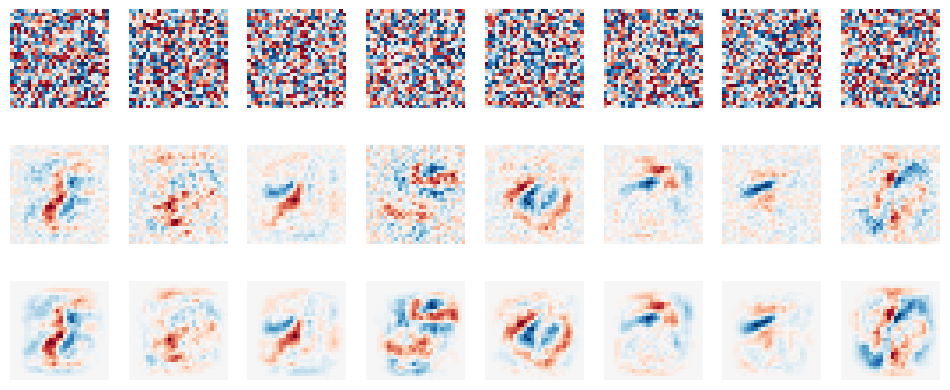

In [20]:
import matplotlib.pyplot as plt
torch.manual_seed(0)
before = MLP() # 같은 seed라 학습 전 초기값과 같다
fig, axes = plt.subplots(3, 8, figsize=(12, 5)) # 학습 전, 학습 후, 변화량
for i in range(8): # 은닉 뉴런 0~7번
    w0 = before.fc1.weight[i].detach().view(28, 28) # 784개 → 28×28
    w1 = model.fc1.weight[i].detach().cpu().view(28, 28)
    for r, w in enumerate([w0, w1, w1 - w0]):
        v = w.abs().max() # 0이 흰색이 되도록 색 범위를 ±v로
        axes[r, i].imshow(w, cmap="RdBu_r", vmin=-v, vmax=v)
        axes[r, i].axis("off")
plt.show()

In [21]:
print(tl) # .item()을 뺀 학습 함수가 돌려준 값
# → tensor(0.4794, device='cuda:0', grad_fn=<DivBackward0>)
print(round(tl, 4)) # 예제 4-11의 출력 줄에서
# → TypeError: type Tensor doesn't define __round__ method

0.07011617262244224
0.0701


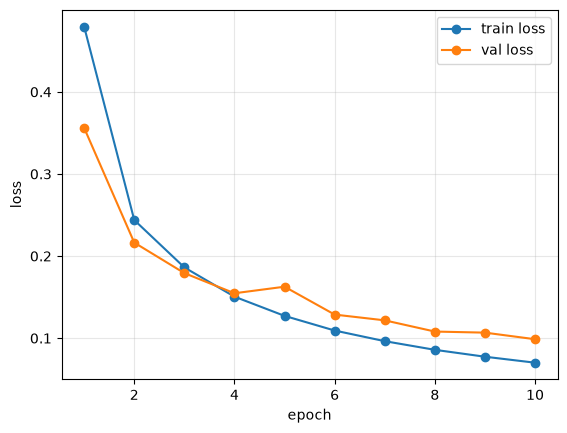

In [22]:
import matplotlib.pyplot as plt
ep = range(1, len(train_losses) + 1) # epoch 번호
plt.plot(ep, train_losses, marker="o", label="train loss")
plt.plot(ep, val_losses, marker="o", label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [24]:
from torch.utils.data import Subset
small_set = Subset(train_set, range(1000)) # 학습 데이터 앞 1,000장만
small_loader = DataLoader(small_set, batch_size=64, shuffle=True)
torch.manual_seed(0) # 여기부터 예제 4-11과 같다
model = MLP().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
train_losses, val_losses, val_accs = [], [], []
for epoch in range(30): # 바꾼 곳 1, 30 epoch
 tl = train_one_epoch(model, small_loader, opt) # 바꾼 곳 2, small_loader
 vl, va = evaluate(model, val_loader)
 train_losses.append(tl)
 val_losses.append(vl)
 val_accs.append(va)
 print(epoch + 1, round(tl, 4), round(vl, 4), round(va, 2))
# → (예) 30 0.1545 0.3996 88.33 (30줄 중 마지막 줄)

1 2.1803 2.0026 50.86
2 1.7737 1.5154 68.28
3 1.2878 1.1107 75.01
4 0.9661 0.8832 79.85
5 0.7734 0.77 79.43
6 0.6642 0.6644 82.97
7 0.5806 0.6415 80.44
8 0.5241 0.5767 84.33
9 0.4797 0.5511 84.05
10 0.4389 0.5229 84.84
11 0.4109 0.4968 85.88
12 0.3815 0.4791 86.7
13 0.3561 0.4703 86.83
14 0.3337 0.451 87.03
15 0.3156 0.447 87.25
16 0.3005 0.4383 87.63
17 0.2861 0.453 86.39
18 0.274 0.4188 87.92
19 0.2592 0.4288 87.16
20 0.2491 0.4141 87.9
21 0.2332 0.4141 87.89
22 0.2201 0.4127 87.86
23 0.2157 0.4094 87.97
24 0.2026 0.4009 88.52
25 0.1939 0.4054 87.86
26 0.1855 0.399 88.43
27 0.1798 0.4066 87.9
28 0.1694 0.4036 88.11
29 0.1656 0.3986 88.24
30 0.1545 0.3996 88.33


In [25]:
train_loss, train_acc = evaluate(model, small_loader) # 2 학습 데이터 1,000장으로 평가
print(round(train_acc, 2), round(va, 2)) # → (예) 97.3 88.33 (학습 데이터와 마지막 epoch의 검증)

97.3 88.33


In [27]:
torch.manual_seed(0) # 조건 고정, seed
model = MLP().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
best_acc, best_epoch = 0.0, 0
for epoch in range(10):
    train_one_epoch(model, train_loader, opt)
    vl, va = evaluate(model, val_loader)
    if va > best_acc: # 검증 최고 기록이면 저장
       best_acc, best_epoch = va, epoch + 1
       torch.save(model.state_dict(), "baseline_mlp.pt")
print(best_epoch, round(best_acc, 2)) # → (예) 10 97.25

10 97.24


In [29]:
import os
state = torch.load("baseline_mlp.pt", map_location=device) # 저장한 파일 열기
for name, w in state.items(): # 계층 이름과 파라미터 묶음
 print(name, tuple(w.shape))
# → fc1.weight (100, 784)
# → fc1.bias (100,)
# → fc2.weight (10, 100)
# → fc2.bias (10,)
print(sum(w.numel() for w in state.values())) # → 79510 (예제 4-6에서 센 개수와 같다)
print(os.path.getsize("baseline_mlp.pt")) # → (예) 320527 (바이트, 약 0.3MB)

fc1.weight (100, 784)
fc1.bias (100,)
fc2.weight (10, 100)
fc2.bias (10,)
79510
320527


In [33]:
test_set = datasets.MNIST(root="data", train=False, download=True,
          transform=transforms.ToTensor()) # 처음 보는 10,000장
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)
model = MLP().to(device) # 새 모델(초기값)에
state = torch.load("baseline_mlp.pt", map_location=device) # 저장한 best 파라미터를
model.load_state_dict(state) # 덮어쓴다
test_loss, test_acc = evaluate(model, test_loader)
print(len(test_set), round(test_acc, 2)) # → (예) 10000 97.34

10000 97.34


In [34]:
torch.manual_seed(0)
model = MLP().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 0.001)
best_acc, best_epoch = 0.0, 0
for epoch in range(10):
    train_one_epoch(model, train_loader, opt)
    vl, va = evaluate(model, val_loader)
    if va > best_acc:
        best_acc, best_epoch = va, epoch + 1
        torch.save(model.state_dict(), "exp1_adam.pt") # 바꾼 곳 2, 파일 이름
print(best_epoch, round(best_acc, 2))

10 97.44


In [35]:
state = torch.load("exp1_adam.pt", map_location=device) # 예제 4-16에서 파일 이름만
model.load_state_dict(state)
test_loss, test_acc = evaluate(model, test_loader)
print(len(test_set), round(test_acc, 2)) # → (예) 10000 97.59

10000 97.61
